In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [5]:
df = pd.read_csv("Iris.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Step 2: Select numerical flower measurements
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[features].dropna()

# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape: (150, 6)

Missing values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


C:\Users\rupesh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rupesh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\rupesh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rupesh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\rupesh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

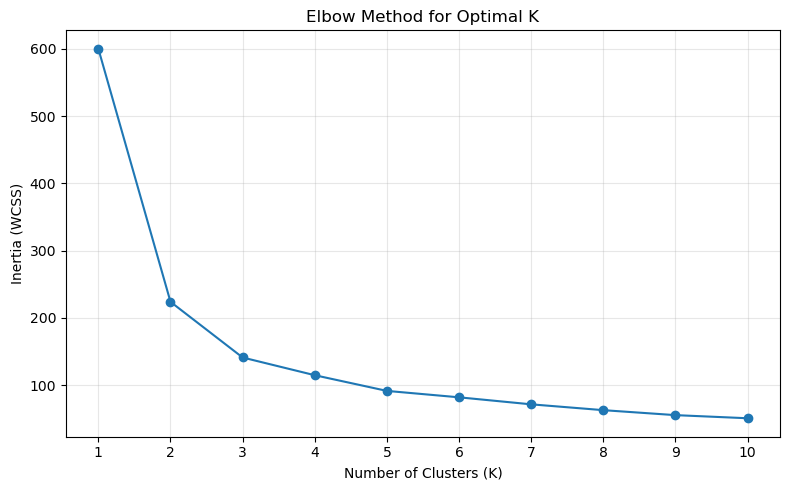

C:\Users\rupesh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [7]:
inertias = []
K_values = range(1, 11)

for k in K_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(K_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Apply K-Means with K = 3
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

clusters = kmeans.fit_predict(X_scaled)



First 10 clustered observations:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Cluster
0            5.1           3.5            1.4           0.2        1
1            4.9           3.0            1.4           0.2        1
2            4.7           3.2            1.3           0.2        1
3            4.6           3.1            1.5           0.2        1
4            5.0           3.6            1.4           0.2        1
5            5.4           3.9            1.7           0.4        1
6            4.6           3.4            1.4           0.3        1
7            5.0           3.4            1.5           0.2        1
8            4.4           2.9            1.4           0.2        1
9            4.9           3.1            1.5           0.1        1

Number of samples in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Cluster centers in original units:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0           5.80 

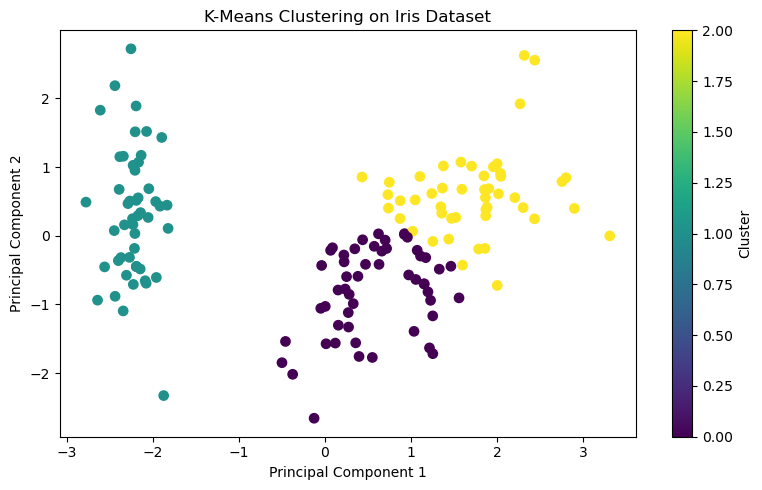

In [9]:
result = df.loc[X.index].copy()
result["Cluster"] = clusters

print("\nFirst 10 clustered observations:")
print(result[features + ["Cluster"]].head(10))

print("\nNumber of samples in each cluster:")
print(result["Cluster"].value_counts().sort_index())

print("\nCluster centers in original units:")
centers = scaler.inverse_transform(kmeans.cluster_centers_)
print(pd.DataFrame(centers, columns=features).round(2))

# Step 7: Reduce to two dimensions for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=clusters,
    cmap="viridis",
    s=45
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering on Iris Dataset")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()
